# Crowdflower Twitter Airline Sentiment Analysis

In [ ]:
%cd /home/hsu/Documents/portfolio_projects/airline_sentiment_analysis/

In [23]:
# Compute SHA256 of raw data file for deterministic provenance tracking
import os
import hashlib
def get_sha256(filepath):
    hasher = hashlib.sha256()
    with open(filepath, 'rb') as f:
        while chunk := f.read(8192):
            hasher.update(chunk)
    return hasher.hexdigest()

## 01 : Get Data

In [20]:
# from scripts import get_data

# # download data and get hash of the dataset
# get_data.fetch_and_record_kaggle_data(
#     dataset_handle="crowdflower/twitter-airline-sentiment",
#     target_dir="./data/twitter_airline_sentiment",
#     metadata_file="./data/twitter_airline_sentiment_metadata.json"
# )

# Downloading crowdflower/twitter-airline-sentiment to cache...
# Copying dataset to ./data/twitter_airline_sentiment...
# Success! Actual dataset saved to './data/twitter_airline_sentiment/' and metadata to './data/twitter_airline_sentiment_metadata.json'

In [21]:
import pandas as pd
import numpy as np

raw_path = "./data/twitter_airline_sentiment/Tweets.csv"
df_raw = pd.read_csv(raw_path)
print(df_raw.info())

df_raw.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created                 14640 non-null  object 
 13  t

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [24]:
raw_source_hash = get_sha256(raw_path) if os.path.exists(raw_path) else "Tweets.csv_not_found"


## 02 : Data Audit

In [7]:
# Create a unique source_row identifier before any transformations
df_raw['source_row'] = np.arange(len(df_raw))

# Ensure tweet_id is treated strictly as a string to prevent precision loss or float conversion
df_raw['tweet_id'] = df_raw['tweet_id'].astype(str)

denominator = len(df_raw)
print(f"Initial Total Rows (Denominator): {denominator}")

Initial Total Rows (Denominator): 14640


In [8]:
print("--- MISSINGNESS AUDIT ---")
missing_counts = df_raw.isnull().sum()
print(missing_counts[missing_counts > 0])
print(f"\nMissingness Denominator: {denominator}\n")

print("--- REPEATED IDs & CONFLICTING LABELS ---")
# Find repeated tweet_ids
id_counts = df_raw['tweet_id'].value_counts()
repeated_ids = id_counts[id_counts > 1].index
print(f"Total repeated tweet_IDs: {len(repeated_ids)}")

# Identify conflicting-label ID groups (same tweet_id, different sentiment)
conflicts = df_raw.groupby('tweet_id')['airline_sentiment'].nunique()
conflicting_ids = conflicts[conflicts > 1].index
print(f"Groups with conflicting sentiment labels: {len(conflicting_ids)}")

print("\n--- AUTHOR/TEXT DUPLICATION ---")
# Check for identical text from the same author
author_text_dupes = df_raw.duplicated(subset=['name', 'text'], keep=False).sum()
print(f"Total rows with duplicated author+text combinations: {author_text_dupes}")

print("\n--- CLASS COUNTS ---")
print(df_raw['airline_sentiment'].value_counts(dropna=False))

--- MISSINGNESS AUDIT ---
negativereason                5462
negativereason_confidence     4118
airline_sentiment_gold       14600
negativereason_gold          14608
tweet_coord                  13621
tweet_location                4733
user_timezone                 4820
dtype: int64

Missingness Denominator: 14640

--- REPEATED IDs & CONFLICTING LABELS ---
Total repeated tweet_IDs: 155
Groups with conflicting sentiment labels: 18

--- AUTHOR/TEXT DUPLICATION ---
Total rows with duplicated author+text combinations: 315

--- CLASS COUNTS ---
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


In [9]:
print("--- NEGATIVEREASON MISSINGNESS BY SENTIMENT ---")
# Cross-tabulate to expose annotation leakage (negativereason is typically only filled for 'negative' sentiment)
leakage_crosstab = pd.crosstab(
    index=df_raw['airline_sentiment'], 
    columns=df_raw['negativereason'].isnull(),
    rownames=['Sentiment'], 
    colnames=['negativereason is NaN']
)
print(leakage_crosstab)
print("\nNote: Perfect or near-perfect correlation between 'negative' sentiment and non-null 'negativereason' indicates severe annotation leakage. This column cannot be used as a predictor.")

--- NEGATIVEREASON MISSINGNESS BY SENTIMENT ---
negativereason is NaN  False  True 
Sentiment                          
negative                9178      0
neutral                    0   3099
positive                   0   2363

Note: Perfect or near-perfect correlation between 'negative' sentiment and non-null 'negativereason' indicates severe annotation leakage. This column cannot be used as a predictor.


In [14]:
# PART 1 — Initialize registry and flag label issues

df_stress = df_raw.copy()
df_stress['audit_flags'] = ''
df_stress['split'] = 'unassigned'

valid_labels = ['negative', 'neutral', 'positive']

conflicts = (
    df_stress.groupby('tweet_id')['airline_sentiment']
    .nunique()
)
conflicting_ids = conflicts[conflicts > 1].index

conflict_mask = df_stress['tweet_id'].isin(conflicting_ids)
missing_label_mask = df_stress['airline_sentiment'].isna()
invalid_label_mask = (
    ~missing_label_mask
    & ~df_stress['airline_sentiment'].isin(valid_labels)
)

def add_audit_flag(mask, flag):
    """Append a reason without overwriting existing flags."""
    existing = df_stress.loc[mask, 'audit_flags']
    df_stress.loc[mask, 'audit_flags'] = (
        existing + '|' + flag
    ).str.strip('|')

add_audit_flag(conflict_mask, 'conflicting_label')
add_audit_flag(missing_label_mask, 'missing_label')
add_audit_flag(invalid_label_mask, 'invalid_label')


# Preliminary eligibility; updated after text/time checks.
df_stress['model_eligible'] = df_stress['audit_flags'].eq('')

assert len(df_stress) == len(df_raw), "Row conservation failed!"


### 03 : Exploration

In [6]:
import re
import unicodedata

# 1. Documented Contraction Handling
# Explicitly expands negations to preserve them prior to any downstream tokenization
CONTRACTION_MAP = {
    "won't": "will not",
    "can't": "can not",
    "n't": " not",
    "'m": " am",
    "'re": " are",
    "'s": " is",
    "'d": " would",
    "'ll": " will",
    "'ve": " have"
}

def normalize_and_clean(text):
    if not isinstance(text, str):
        return ""
    
    # Deterministic Unicode Normalization (NFKC standardizes width/compatibility characters)
    text = unicodedata.normalize('NFKC', text)
    
    # Stable URL and Mention Markers
    text = re.sub(r'http\S+|www\S+|https\S+', '<URL>', text, flags=re.IGNORECASE)
    text = re.sub(r'@\w+', '<USER>', text)
    
    # Lowercase for uniform contraction matching
    text = text.lower()
    
    # Contraction Expansion
    for contraction, expansion in CONTRACTION_MAP.items():
        text = text.replace(contraction, expansion)
        
    # Preserve hashtag words (strip the '#' symbol but keep the alphanumeric content)
    text = re.sub(r'#(\w+)', r'\1', text)
    
    # Whitespace normalization: strip leading/trailing and compress multiple spaces
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

# Define what constitutes a "token"
# Tokenizer rule: Extracts words (alphanumeric), our stable markers (<URL>, <USER>), and standalone emojis/symbols.
def tokenize(clean_text):
    # Matches <USER>, <URL>, contiguous word characters, or non-whitespace non-word characters (like emojis)
    return re.findall(r'<url>|<user>|\w+|[^\w\s]', clean_text)

In [11]:
print("--- RAW / CLEAN PAIRS ---")
sample_tweets = [
    # 1. Negation & Mentions
    "@VirginAmerica I can't believe how bad this flight was.",
    # 2. URLs & Emoji
    "Flight delayed again 😡 [http://t.co/frustration](http://t.co/frustration)",
    # 3. Hashtags & Negation
    "We won't be flying with you again #terribleService",
    # 4. Complex formatting & Mentions
    "Hey @united,    why is my bag in Denver??? \u210C", # \u210C is a unicode stylized H
    # 5. Multiple markers & standard text
    "@SouthwestAir is doing a great job! #flying [http://southwest.com](http://southwest.com) 😊"
]

for i, raw in enumerate(sample_tweets, 1):
    clean = normalize_and_clean(raw)
    tokens = tokenize(clean)
    print(f"Pair {i}:")
    print(f"  Raw:    {raw}")
    print(f"  Clean:  {clean}")
    print(f"  Tokens: {tokens}\n")

--- RAW / CLEAN PAIRS ---
Pair 1:
  Raw:    @VirginAmerica I can't believe how bad this flight was.
  Clean:  <user> i can not believe how bad this flight was.
  Tokens: ['<user>', 'i', 'can', 'not', 'believe', 'how', 'bad', 'this', 'flight', 'was', '.']

Pair 2:
  Raw:    Flight delayed again 😡 [http://t.co/frustration](http://t.co/frustration)
  Clean:  flight delayed again 😡 [<url>
  Tokens: ['flight', 'delayed', 'again', '😡', '[', '<url>']

Pair 3:
  Raw:    We won't be flying with you again #terribleService
  Clean:  we will not be flying with you again terribleservice
  Tokens: ['we', 'will', 'not', 'be', 'flying', 'with', 'you', 'again', 'terribleservice']

Pair 4:
  Raw:    Hey @united,    why is my bag in Denver??? ℌ
  Clean:  hey <user>, why is my bag in denver??? h
  Tokens: ['hey', '<user>', ',', 'why', 'is', 'my', 'bag', 'in', 'denver', '?', '?', '?', 'h']

Pair 5:
  Raw:    @SouthwestAir is doing a great job! #flying [http://southwest.com](http://southwest.com) 😊
  Clean:

In [12]:
print("--- UNSAFE DELETION: 'GOOD' VS 'NOT GOOD' ---")
# Standard stopword lists (like NLTK's default) often contain "not".
# Deleting it destroys the sentiment valence entirely.

unsafe_stopwords = {'not', 'is', 'was', 'a', 'the', 'to', 'be'}

phrase_1 = "good"
phrase_2 = "not good"

clean_1 = normalize_and_clean(phrase_1)
clean_2 = normalize_and_clean(phrase_2)

# Apply unsafe deletion
unsafe_tokens_1 = [t for t in tokenize(clean_1) if t not in unsafe_stopwords]
unsafe_tokens_2 = [t for t in tokenize(clean_2) if t not in unsafe_stopwords]

print(f"Phrase 1 ('{phrase_1}'): Safe Tokens -> {tokenize(clean_1)} | Unsafe Deletion -> {unsafe_tokens_1}")
print(f"Phrase 2 ('{phrase_2}'): Safe Tokens -> {tokenize(clean_2)} | Unsafe Deletion -> {unsafe_tokens_2}")
print("Result: After unsafe deletion, 'not good' becomes identical to 'good', completely erasing the negative label predictor.")

print("\n--- ARITHMETIC EXAMPLES ---")
# Arithmetic Example 1: Token length math with contraction expansion
# "won't" (1 word) -> "will not" (2 words)
raw_math_1 = "won't"
tokens_math_1 = tokenize(normalize_and_clean(raw_math_1))
print(f"Example 1: len('{raw_math_1}'.split()) = 1 token, but len({tokens_math_1}) = {len(tokens_math_1)} tokens.")
assert len(tokens_math_1) == len(raw_math_1.split()) + 1

# Arithmetic Example 2: Token length math with unsafe deletion
# "not good" (2 tokens) - "not" (1 stopword) = 1 token
raw_math_2 = "not good"
safe_len = len(tokenize(normalize_and_clean(raw_math_2)))
unsafe_len = len(unsafe_tokens_2)
print(f"Example 2: Safe length ({safe_len}) - Stopword drop ({safe_len - unsafe_len}) = Unsafe length ({unsafe_len}).")
assert unsafe_len == safe_len - 1

--- UNSAFE DELETION: 'GOOD' VS 'NOT GOOD' ---
Phrase 1 ('good'): Safe Tokens -> ['good'] | Unsafe Deletion -> ['good']
Phrase 2 ('not good'): Safe Tokens -> ['not', 'good'] | Unsafe Deletion -> ['good']
Result: After unsafe deletion, 'not good' becomes identical to 'good', completely erasing the negative label predictor.

--- ARITHMETIC EXAMPLES ---
Example 1: len('won't'.split()) = 1 token, but len(['will', 'not']) = 2 tokens.
Example 2: Safe length (2) - Stopword drop (1) = Unsafe length (1).


### 04 : Preparation

Groups related tweets into connected components, so tweets linked by the same author or identical cleaned text receive the same component_id. This can help prevent related tweets from leaking across training and test sets.

In [15]:
# PART 2 — Clean text, validate timestamps, finalize eligibility


# Apply cleaning and measure token lengths
df_stress['text_clean'] = (
    df_stress['text'].apply(normalize_and_clean)
)

df_stress['token_length'] = (
    df_stress['text_clean'].apply(lambda text: len(tokenize(text)))
)

df_stress['tweet_created'] = pd.to_datetime(
    df_stress['tweet_created'],
    errors='coerce',
    utc=True
)

empty_text_mask = df_stress['text_clean'].fillna('').str.strip().eq('')
zero_token_mask = df_stress['token_length'].eq(0)
invalid_time_mask = df_stress['tweet_created'].isna()

add_audit_flag(empty_text_mask, 'empty_text')
add_audit_flag(zero_token_mask, 'zero_tokens')
add_audit_flag(invalid_time_mask, 'invalid_time')

# Single source of truth for all subsequent filtering.
df_stress['model_eligible'] = df_stress['audit_flags'].eq('')

print(f"Total source rows: {len(df_stress):,}")
print(f"Eligible rows: {df_stress['model_eligible'].sum():,}")
print(f"Ineligible rows: {(~df_stress['model_eligible']).sum():,}")

Total source rows: 14,640
Eligible rows: 14,604
Ineligible rows: 36


In [16]:
# PART 3 — Filter once, build components, select representatives
# 
import networkx as nx

valid_mask = df_stress['model_eligible']
df_valid = df_stress.loc[valid_mask].copy()
assert df_valid['source_row'].is_unique, "source_row must be unique!" 


# 1. Component Deduplication (Graph Linking)
# Build Graph: Nodes = source_row
G = nx.Graph()
G.add_nodes_from(df_valid['source_row'])

# Link shared nonmissing, nonblank authors.
for author, group in df_valid.groupby('name'):
    if pd.isna(author) or str(author).strip() == '':
        continue
    source_rows = group['source_row'].tolist()
    for i in range(1, len(source_rows)):
        G.add_edge(source_rows[0], source_rows[i])

# Link exact nonempty normalized text.
for text_val, group in df_valid.groupby('text_clean'):
    if pd.isna(text_val) or str(text_val).strip() == '':
        continue
    source_rows = group['source_row'].tolist()
    for i in range(1, len(source_rows)):
        G.add_edge(source_rows[0], source_rows[i])

# Map components
comp_dict = {
    node: comp_id
    for comp_id, nodes in enumerate(nx.connected_components(G))
    for node in nodes
}

df_stress['component_id'] = (
    df_stress['source_row'].map(comp_dict).astype('Int64')
)
df_valid['component_id'] = (
    df_valid['source_row'].map(comp_dict).astype('Int64')
)

df_valid_sorted = df_valid.sort_values(
    ['tweet_created', 'tweet_id', 'source_row']
)

df_reps = (
    df_valid_sorted.groupby('component_id', sort=False)
    .head(1)
    .copy()
)

assert len(df_stress) == len(df_raw), "Row conservation failed!"
assert len(df_valid) == df_stress['model_eligible'].sum()
assert df_reps['component_id'].is_unique

print(f"Valid pool: {len(df_valid):,}")
print(f"Component representatives: {len(df_reps):,}")

Valid pool: 14,604
Component representatives: 7,551


In [ ]:
# 2. Stratified Train/Test Split
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer


# Isolate features (X) and target (y) for the split
X = df_reps[['source_row', 'tweet_id', 'text', 'text_clean', 'name']]
y = df_reps['airline_sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=961731, stratify=y
)

# Record the split in the main registry
df_stress.loc[X_train.index, 'split'] = 'train'
df_stress.loc[X_test.index, 'split'] = 'test'

df_train = df_stress[df_stress['split'] == 'train'].copy()
df_test = df_stress[df_stress['split'] == 'test'].copy()

# Key manifests and prediction joins by source_row plus tweet_id
manifest_train = df_train[['source_row', 'tweet_id', 'airline_sentiment']]
manifest_test = df_test[['source_row', 'tweet_id', 'airline_sentiment']]


# 3. Assertions (Disjoint Sets)

assert set(df_train['tweet_id']).isdisjoint(set(df_test['tweet_id'])), "ID leakage!"
assert set(df_train['name'].dropna()).isdisjoint(set(df_test['name'].dropna())), "Author leakage!"
assert set(df_train['text_clean']).isdisjoint(set(df_test['text_clean'])), "Text leakage!"


Rows before selection: 14604
Unique components: 7551
Rows in df_reps: 7551
Repeated component IDs: 0


In [38]:
# 4. Denominator Audit & Explanations

total_source = len(df_stress)
quarantined = (~df_stress['model_eligible']).sum()
valid_pool = valid_mask.sum()
independent_reps = len(df_reps)
train_count = len(df_train)
test_count = len(df_test)

print("=== DENOMINATOR AUDIT & EXPLANATIONS ===")
audit_df = pd.DataFrame({
    "Stage": [
        "1. Total Source Posts", 
        "2. Quarantined / Ineligible", 
        "3. Valid Pool", 
        "4. Independent Representatives", 
        "5. Training Set", 
        "6. Testing Set"
    ],
    "Count": [total_source, quarantined, valid_pool, independent_reps, train_count, test_count],
    "Explanation": [
        "Full registry counts check ingestion; includes all duplicates, errors, and injected defects.",
        "Rows excluded from modeling due to missing labels, conflicting ID groups, or zero-feature text.",
        "Rows meeting baseline criteria before graph-based deduplication.",
        "Deduplicated modeling representatives (1 per connected author/text component).",
        "80% stratified sample of independent reps. Detailed feature decisions use this data only.",
        "20% locked evaluation set. Does not establish future-period performance."
    ]
})
pd.set_option('display.max_colwidth', None)
print(audit_df.to_string(index=False))
print("\n")


=== DENOMINATOR AUDIT & EXPLANATIONS ===
                         Stage  Count                                                                                     Explanation
         1. Total Source Posts  14640    Full registry counts check ingestion; includes all duplicates, errors, and injected defects.
   2. Quarantined / Ineligible     36 Rows excluded from modeling due to missing labels, conflicting ID groups, or zero-feature text.
                 3. Valid Pool  14604                                Rows meeting baseline criteria before graph-based deduplication.
4. Independent Representatives   7551                  Deduplicated modeling representatives (1 per connected author/text component).
               5. Training Set   6040       80% stratified sample of independent reps. Detailed feature decisions use this data only.
                6. Testing Set   1511                        20% locked evaluation set. Does not establish future-period performance.




/tmp/ipykernel_177/1225158976.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_reps, x='airline_sentiment', order=['negative', 'neutral', 'positive'],
/tmp/ipykernel_177/1225158976.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bigram_freq, x='frequency', y='bigram', ax=axes[2], palette='viridis')


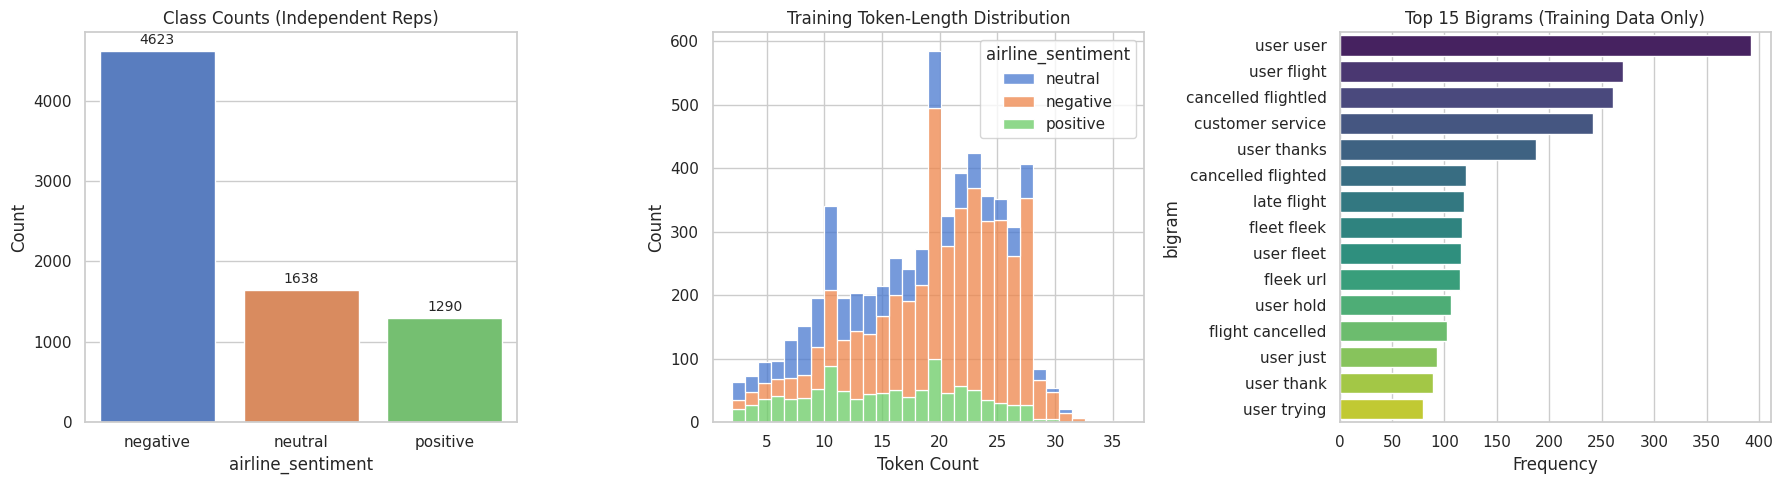

=== RAW / CLEAN EXAMPLES (From Training Fold) ===
RAW:   @AmericanAir Extend rtn flight to bereavement, 22nd I could have change fee dropped, now told no.Worse day of my life #badcustomerservice
CLEAN: <user> extend rtn flight to bereavement, 22nd i could have change fee dropped, now told no.worse day of my life badcustomerservice

RAW:   @united still sucks. I don't understand why you have two cust service agents for a long line at Houston international b gate #unitedsucks
CLEAN: <user> still sucks. i do not understand why you have two cust service agents for a long line at houston international b gate unitedsucks

RAW:   @USAirways if there are empty first class seats on my flight at check in, why wouldn't I be automatically upgraded?
CLEAN: <user> if there are empty first class seats on my flight at check in, why would not i be automatically upgraded?

RAW:   @SouthwestAir I will say that your customer service has consistently been the very best!!!
CLEAN: <user> i will say that your

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 5. Visualizations (Fit strictly on Training Fold)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot A: Labeled Class-Count Bars (Using the modeling representatives)
sns.countplot(data=df_reps, x='airline_sentiment', order=['negative', 'neutral', 'positive'], 
              ax=axes[0], palette='muted')
axes[0].set_title("Class Counts (Independent Reps)")
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# Plot B: Training Token-Length Distributions
df_train['token_length'] = df_train['text_clean'].apply(lambda x: len(x.split()))
sns.histplot(data=df_train, x='token_length', hue='airline_sentiment', 
             multiple='stack', bins=30, ax=axes[1], palette='muted')
axes[1].set_title("Training Token-Length Distribution")
axes[1].set_xlabel("Token Count")

# Plot C: Training Bigram Bars (Vocabulary/IDF fit strictly inside training fold)
vectorizer = CountVectorizer(ngram_range=(2, 2), max_features=15, stop_words='english')
X_bigrams = vectorizer.fit_transform(df_train['text_clean'])
bigram_sums = X_bigrams.sum(axis=0).A1
bigram_freq = pd.DataFrame({'bigram': vectorizer.get_feature_names_out(), 'frequency': bigram_sums})
bigram_freq = bigram_freq.sort_values(by='frequency', ascending=False)

sns.barplot(data=bigram_freq, x='frequency', y='bigram', ax=axes[2], palette='viridis')
axes[2].set_title("Top 15 Bigrams (Training Data Only)")
axes[2].set_xlabel("Frequency")

plt.tight_layout()
plt.show()


# 6. Raw / Clean Examples

print("=== RAW / CLEAN EXAMPLES (From Training Fold) ===")
sample_train = df_train[['text', 'text_clean']].sample(5, random_state=42)
for idx, row in sample_train.iterrows():
    print(f"RAW:   {row['text']}")
    print(f"CLEAN: {row['text_clean']}\n")

### 2. Modelling

In [45]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
import scipy.sparse


# 1. Feature Extraction (Strictly Text-Derived, Sparse Storage)

# Isolate text features only; metadata is strictly excluded from training
X_train_text = df_train['text_clean']
y_train = df_train['airline_sentiment']

X_test_text = df_test['text_clean']
y_test = df_test['airline_sentiment']

# Configure TF-IDF per specifications
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),    # Unigram and bigram features
    sublinear_tf=True,     # Sublinear TF scaling (1 + log(tf))
    smooth_idf=True,       # Smoothed IDF
    norm='l2'              # L2 normalization
)

# Fit vocabulary on training fold ONLY, outputting sparse matrices
X_train_vec = vectorizer.fit_transform(X_train_text)
X_test_vec = vectorizer.transform(X_test_text)

# Assert preservation of sparse storage (do NOT use .toarray())
assert scipy.sparse.issparse(X_train_vec), "Training features lost sparse format!"
assert scipy.sparse.issparse(X_test_vec), "Testing features lost sparse format!"


In [46]:

# 2. Dummy Classifier (Baseline)

# Strategy 'prior' predicts the argmax of the training class distribution
dummy_clf = DummyClassifier(strategy='prior')
dummy_clf.fit(X_train_vec, y_train)

print("=== DUMMY CLASSIFIER ===")
print(f"Declared Strategy: {dummy_clf.strategy}")
print(f"Class Order: {dummy_clf.classes_}")

# Generate argmax predictions
y_pred_dummy = dummy_clf.predict(X_test_vec)

print("\nDummy Classification Report:")
print(classification_report(y_test, y_pred_dummy, zero_division=0))

=== DUMMY CLASSIFIER ===
Declared Strategy: prior
Class Order: ['negative' 'neutral' 'positive']

Dummy Classification Report:
              precision    recall  f1-score   support

    negative       0.61      1.00      0.76       925
     neutral       0.00      0.00      0.00       328
    positive       0.00      0.00      0.00       258

    accuracy                           0.61      1511
   macro avg       0.20      0.33      0.25      1511
weighted avg       0.37      0.61      0.46      1511



In [47]:


# 3. L2-Regularized Multinomial Logistic Regression

log_reg = LogisticRegression(
    penalty='l2',                  # L2-regularization
    multi_class='multinomial',     # Multinomial (softmax) strategy
    solver='lbfgs',                # Standard solver for L2 multinomial
    max_iter=1000,
    random_state=961731
)

log_reg.fit(X_train_vec, y_train)
y_pred_log = log_reg.predict(X_test_vec)

print("=== LOGISTIC REGRESSION ===")
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_log))



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


=== LOGISTIC REGRESSION ===
Logistic Regression Classification Report:
              precision    recall  f1-score   support

    negative       0.76      0.97      0.85       925
     neutral       0.77      0.42      0.55       328
    positive       0.85      0.53      0.65       258

    accuracy                           0.77      1511
   macro avg       0.79      0.64      0.68      1511
weighted avg       0.78      0.77      0.75      1511



In [49]:

# 4. Evaluation Explanations

dummy_acc = accuracy_score(y_test, y_pred_dummy)
log_acc = accuracy_score(y_test, y_pred_log)

print(f"Dummy Accuracy: {dummy_acc:.1%}")
print(f"Logistic Regression Accuracy: {log_acc:.1%}")


Dummy Accuracy: 61.2%
Logistic Regression Accuracy: 77.4%


**Why Accuracy Alone Hides Weak Minority Class Performance**

* When looking only at accuracy, the Dummy accuracy is 61.2%, but that 61.2% is only for the negative class due to class imbalance. The model seems correct only for the negative class and cannot predict the other classes, as seen by their F1 scores of 0.0.

### 2.2 Hyperparameter Selection Using Training-Only Cross-Validation

In [50]:
import time
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score


# 1. Predeclare Bounded Comparison & Parameter Grid

# BOUNDED COMPARISON: Unigram-only (1,1) versus Unigram+Bigram (1,2) features.
# We will evaluate this alongside the C hyperparameter search strictly within the training folds.
ngram_options = [(1, 1), (1, 2)]
C_values = [0.3, 1.0, 3.0]


# 2. Stratified Cross-Validation Setup

# 3 stratified training-only folds with shuffle and fixed seed
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=961731)

results = []
best_f1 = -1
best_params = None

print("Starting Cross-Validation (Training Data Only)...\n")


# 3. Execution (Iterating through candidates)

for ngram in ngram_options:
    for C in C_values:
        fold_f1_scores = []
        fold_fit_times = []
        fold_convergence = []
        
        # Iterate over folds
        for train_idx, val_idx in skf.split(X_train_text, y_train):
            # Isolate fold data
            X_fold_train, X_fold_val = X_train_text.iloc[train_idx], X_train_text.iloc[val_idx]
            y_fold_train, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
            
            # Construct monolithic pipeline per requirements
            pipeline = Pipeline([
                ('tfidf', TfidfVectorizer(
                    max_features=5000, 
                    min_df=2, 
                    sublinear_tf=True, 
                    smooth_idf=True, 
                    norm='l2', 
                    ngram_range=ngram
                )),
                ('clf', LogisticRegression(
                    C=C, 
                    penalty='l2', 
                    multi_class='multinomial', 
                    solver='lbfgs', 
                    max_iter=1000, 
                    random_state=961731
                ))
            ])
            
            # Measure fit time
            start_time = time.time()
            pipeline.fit(X_fold_train, y_fold_train)
            fit_time = time.time() - start_time
            
            # Evaluate on validation fold
            y_fold_pred = pipeline.predict(X_fold_val)
            f1 = f1_score(y_fold_val, y_fold_pred, average='macro')
            
            # Extract convergence status
            clf_step = pipeline.named_steps['clf']
            # n_iter_ returns an array (1, ); if it's less than max_iter, it converged
            converged = clf_step.n_iter_[0] < clf_step.max_iter
            
            fold_f1_scores.append(f1)
            fold_fit_times.append(fit_time)
            fold_convergence.append(converged)
            
        # Aggregate candidate metrics across the 3 folds
        mean_f1 = np.mean(fold_f1_scores)
        
        results.append({
            'ngram_range': str(ngram),
            'C': C,
            'mean_macro_F1': mean_f1,
            'mean_fit_time_sec': np.mean(fold_fit_times),
            'all_folds_converged': all(fold_convergence)
        })
        
        # Track the best pipeline parameters
        if mean_f1 > best_f1:
            best_f1 = mean_f1
            best_params = {'ngram_range': ngram, 'C': C}


# 4. Review Results & Select Best Pipeline

df_cv_results = pd.DataFrame(results)
print("=== CROSS-VALIDATION RESULTS ===")
print(df_cv_results.to_string(index=False))

print(f"\nBest Parameters Selected: ngram_range={best_params['ngram_range']}, C={best_params['C']}")
print(f"Best Mean Macro-F1 Score: {best_f1:.4f}")


Starting Cross-Validation (Training Data Only)...



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

=== CROSS-VALIDATION RESULTS ===
ngram_range   C  mean_macro_F1  mean_fit_time_sec  all_folds_converged
     (1, 1) 0.3       0.599642           0.223439                 True
     (1, 1) 1.0       0.688853           0.328259                 True
     (1, 1) 3.0       0.706964           0.410109                 True
     (1, 2) 0.3       0.568658           1.254675                 True
     (1, 2) 1.0       0.688457           1.604920                 True
     (1, 2) 3.0       0.703703           1.849340                 True

Best Parameters Selected: ngram_range=(1, 1), C=3.0
Best Mean Macro-F1 Score: 0.7070


In [ ]:
# 5. Refit Selected Pipeline on ALL Training Representatives

# Note: The locked test set (X_test_text, y_test) remains untouched.
final_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=5000, 
        min_df=2, 
        sublinear_tf=True, 
        smooth_idf=True, 
        norm='l2', 
        ngram_range=best_params['ngram_range']
    )),
    ('clf', LogisticRegression(
        C=best_params['C'], 
        penalty='l2', 
        multi_class='multinomial', 
        solver='lbfgs', 
        max_iter=1000, 
        random_state=961731
    ))
])

print("\nRefitting the final pipeline on all training representatives...")
final_pipeline.fit(X_train_text, y_train)

# Final convergence check on the full train set
final_clf = final_pipeline.named_steps['clf']
final_converged = final_clf.n_iter_[0] < final_clf.max_iter
print(f"Final model converged: {final_converged} (Iterations: {final_clf.n_iter_[0]}/{final_clf.max_iter})")


Refitting the final pipeline on all training representatives...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Final model converged: True (Iterations: 67/1000)


### 2.3 Test Set Evaluation and Error Analysis


In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    log_loss,
    confusion_matrix,
    classification_report
)


# 1. Open the Locked Test Set (Evaluation Phase)

# Pipeline is frozen; do NOT fit or modify vectorizer/classifier parameters here.
y_test_true = df_test['airline_sentiment']
y_test_pred = final_pipeline.predict(df_test['text_clean'])
y_test_proba = final_pipeline.predict_proba(df_test['text_clean'])

classes = final_pipeline.classes_


# 2. Performance Metrics & Formula Declarations

# Zero-Denominator Convention:
# Precision = TP / (TP + FP); if (TP + FP) == 0, Precision is assigned 0.0.
# Recall    = TP / (TP + FN); if (TP + FN) == 0, Recall is assigned 0.0.
# zero_division=0 enforces this standard convention deterministically.

acc = accuracy_score(y_test_true, y_test_pred)
macro_f1 = f1_score(y_test_true, y_test_pred, average='macro', zero_division=0)
loss = log_loss(y_test_true, y_test_proba, labels=classes)

print("=== OVERALL METRICS ON LOCKED TEST SET ===")
print(f"Accuracy:         {acc:.4f}")
print(f"Macro-F1 Score:   {macro_f1:.4f}")
print(f"Multiclass LogLoss: {loss:.4f}\n")

# Detailed per-class precision, recall, F1, and support
print("=== PER-CLASS METRICS & SUPPORT ===")
print(f"Declared Class Order: {list(classes)}")
print(classification_report(y_test_true, y_test_pred, labels=classes, digits=4, zero_division=0))


=== OVERALL METRICS ON LOCKED TEST SET ===
Accuracy:         0.7935
Macro-F1 Score:   0.7276
Multiclass LogLoss: 0.5132

=== PER-CLASS METRICS & SUPPORT ===
Declared Class Order: ['negative', 'neutral', 'positive']
              precision    recall  f1-score   support

    negative     0.8219    0.9232    0.8697       925
     neutral     0.7020    0.5457    0.6141       328
    positive     0.7650    0.6434    0.6989       258

    accuracy                         0.7935      1511
   macro avg     0.7630    0.7041    0.7276      1511
weighted avg     0.7862    0.7935    0.7850      1511



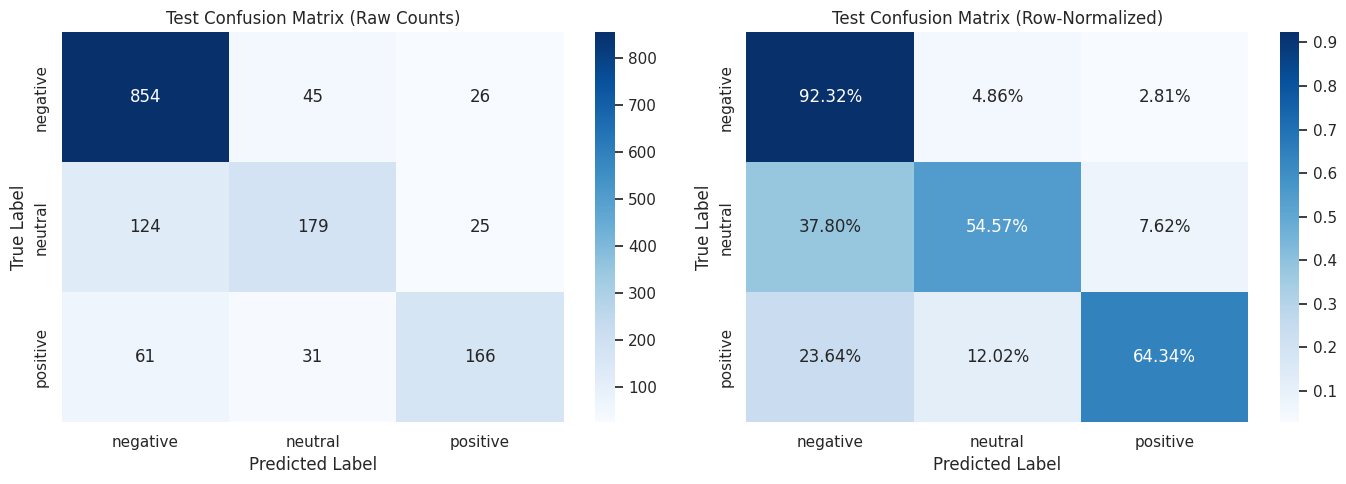

In [53]:

# 3. Count & Row-Normalized Confusion Matrices

cm_count = confusion_matrix(y_test_true, y_test_pred, labels=classes)
cm_normalized = confusion_matrix(y_test_true, y_test_pred, labels=classes, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw Count Matrix
sns.heatmap(cm_count, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=classes, yticklabels=classes)
axes[0].set_title("Test Confusion Matrix (Raw Counts)")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# Row-Normalized Matrix (Recall / True-Class Rates)
sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='Blues', ax=axes[1],
            xticklabels=classes, yticklabels=classes)
axes[1].set_title("Test Confusion Matrix (Row-Normalized)")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()


In [54]:

# 4. Error Sample Analysis (Human Review)

# Key manifests and joins by source_row + tweet_id
df_test_errors = df_test.copy()
df_test_errors['predicted_sentiment'] = y_test_pred
for i, cls in enumerate(classes):
    df_test_errors[f'proba_{cls}'] = y_test_proba[:, i]

# Filter down to misclassifications
misclassifications = df_test_errors[df_test_errors['airline_sentiment'] != df_test_errors['predicted_sentiment']]

# Inspect a fixed-seed sample of 10 errors
sample_errors = misclassifications[[
    'source_row', 'tweet_id', 'text', 'text_clean', 
    'airline_sentiment', 'predicted_sentiment'
]].sample(n=10, random_state=961731)

print("=== FIXED-SEED ERROR AUDIT SAMPLE (Seed 961731) ===")
# Note: Error categories (negation, sarcasm, spelling, mixed sentiment) 
# represent post-hoc human review and diagnostics, NOT ground-truth source annotations.
for idx, row in sample_errors.iterrows():
    print(f"source_row: {row['source_row']} | tweet_id: {row['tweet_id']}")
    print(f"Raw Text:   {row['text']}")
    print(f"Clean Text: {row['text_clean']}")
    print(f"True Label: {row['airline_sentiment']} | Predicted: {row['predicted_sentiment']}\n")

=== FIXED-SEED ERROR AUDIT SAMPLE (Seed 961731) ===
source_row: 5588 | tweet_id: 568882182686707712
Raw Text:   @SouthwestAir thanks for losing my luggage
Clean Text: <user> thanks for losing my luggage
True Label: negative | Predicted: positive

source_row: 4692 | tweet_id: 569927965007417344
Raw Text:   @SouthwestAir Thanks. I did go through these motions shortly after my flight yesterday. I wonder how quickly flight attendants are notified.
Clean Text: <user> thanks. i did go through these motions shortly after my flight yesterday. i wonder how quickly flight attendants are notified.
True Label: positive | Predicted: neutral

source_row: 4992 | tweet_id: 569567028136296450
Raw Text:   @SouthwestAir my flight continues through to Vegas after my stop. Don't be upset if a stowaway.
Clean Text: <user> my flight continues through to vegas after my stop. do not be upset if a stowaway.
True Label: neutral | Predicted: negative

source_row: 7994 | tweet_id: 568895587900207104
Raw Text:   @J

In [55]:
# Display row-normalized breakdown table in plain text for reporting
df_norm = pd.DataFrame(cm_normalized, index=[f"True: {c}" for c in classes], 
                       columns=[f"Pred: {c}" for c in classes])
print("Row-Normalized Confusion Matrix (Recall on Diagonal):")
print((df_norm * 100).round(2).astype(str) + "%")

Row-Normalized Confusion Matrix (Recall on Diagonal):
               Pred: negative Pred: neutral Pred: positive
True: negative         92.32%         4.86%          2.81%
True: neutral           37.8%        54.57%          7.62%
True: positive         23.64%        12.02%         64.34%


## 2.4 Model Interpretation: Top Positive Coefficients & Local Contrast

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract vectorizer and classifier steps from the refitted final pipeline
vectorizer = final_pipeline.named_steps['tfidf']
clf = final_pipeline.named_steps['clf']

feature_names = np.array(vectorizer.get_feature_names_out())
classes = clf.classes_
coef = clf.coef_          # Shape: (n_classes, n_features)
intercepts = clf.intercept_  # Shape: (n_classes,)

/tmp/ipykernel_177/1759970740.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_weights, y=top10_features, ax=axes[idx], palette="Blues_r")
/tmp/ipykernel_177/1759970740.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_weights, y=top10_features, ax=axes[idx], palette="Blues_r")
/tmp/ipykernel_177/1759970740.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_weights, y=top10_features, ax=axes[idx], palette="Blues_r")


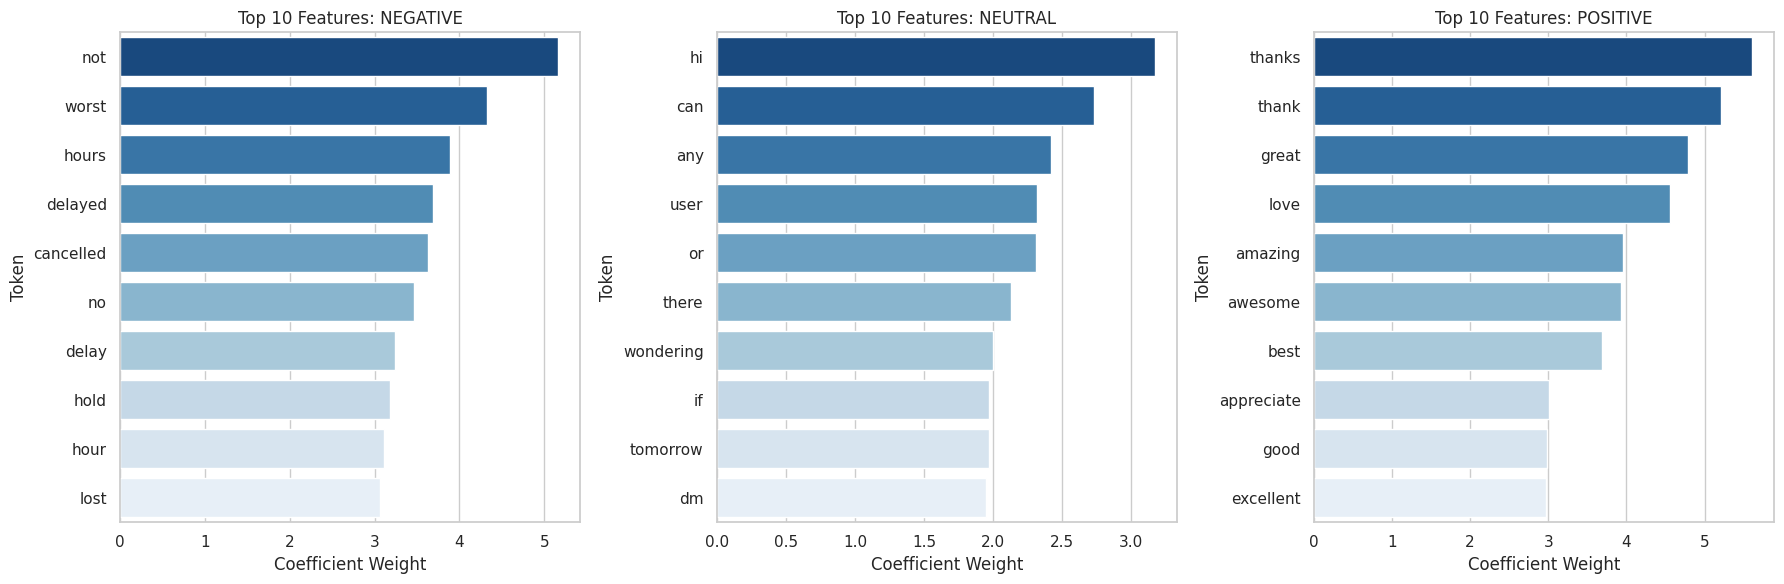

In [58]:

# 1. Plot Ten Largest Positive Coefficients Per Class

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=False)
sns.set_theme(style="whitegrid")

for idx, class_name in enumerate(classes):
    class_coef = coef[idx]
    top10_idx = np.argsort(class_coef)[-10:][::-1]
    top10_weights = class_coef[top10_idx]
    top10_features = feature_names[top10_idx]
    
    sns.barplot(x=top10_weights, y=top10_features, ax=axes[idx], palette="Blues_r")
    axes[idx].set_title(f"Top 10 Features: {class_name.upper()}")
    axes[idx].set_xlabel("Coefficient Weight")
    axes[idx].set_ylabel("Token")

plt.tight_layout()
plt.show()

In [60]:
# 2. Local Contrast: Predicted Class vs. Runner-Up Class

# Select an instance from the locked test set (fixed index)
sample_idx = 0
sample_text = df_test['text_clean'].iloc[sample_idx]
sample_raw = df_test['text'].iloc[sample_idx]
source_row = df_test['source_row'].iloc[sample_idx]
tweet_id = df_test['tweet_id'].iloc[sample_idx]

# Extract transformed sparse feature vector and probabilities
sample_vec = vectorizer.transform([sample_text])
sample_probs = clf.predict_proba(sample_vec)[0]

# Compute raw logit scores: z_k = w_k * x + b_k
# linear_scores = sample_vec.dot(coef.T).toarray()[0] + intercepts
# Compute raw logit scores directly using scikit-learn
linear_scores = clf.decision_function(sample_vec)[0]

# Identify top predicted class and runner-up class
ranked_class_indices = np.argsort(linear_scores)[::-1]
pred_idx = ranked_class_indices[0]
runner_up_idx = ranked_class_indices[1]

pred_class = classes[pred_idx]
runner_up_class = classes[runner_up_idx]

print("=== LOCAL CONTRAST AUDIT ===")
print(f"source_row: {source_row} | tweet_id: {tweet_id}")
print(f"Raw Text:   {sample_raw}")
print(f"Clean Text: {sample_text}")
print(f"Predicted Class: '{pred_class}' (Score: {linear_scores[pred_idx]:.5f}, Proba: {sample_probs[pred_idx]:.4f})")
print(f"Runner-Up Class: '{runner_up_class}' (Score: {linear_scores[runner_up_idx]:.5f}, Proba: {sample_probs[runner_up_idx]:.4f})\n")

=== LOCAL CONTRAST AUDIT ===
source_row: 2 | tweet_id: 570301083672813571
Raw Text:   @VirginAmerica I didn't today... Must mean I need to take another trip!
Clean Text: <user> i did not today... must mean i need to take another trip!
Predicted Class: 'neutral' (Score: 0.58980, Proba: 0.4919)
Runner-Up Class: 'negative' (Score: 0.39991, Proba: 0.4068)



In [61]:

# 3. Score Difference Decomposition & Numerical Verification

# Actual score difference
score_diff = linear_scores[pred_idx] - linear_scores[runner_up_idx]

# Component 1: Intercept difference
intercept_diff = intercepts[pred_idx] - intercepts[runner_up_idx]

# Component 2: Feature-level weight differences * feature values
# Delta w = w_pred - w_runner_up
delta_w = coef[pred_idx] - coef[runner_up_idx]

# Active tokens present in the sample text
sample_coo = sample_vec.tocoo()
active_feature_indices = sample_coo.col
active_feature_values = sample_coo.data

contributions = []
for f_idx, x_val in zip(active_feature_indices, active_feature_values):
    feature_token = feature_names[f_idx]
    w_pred = coef[pred_idx, f_idx]
    w_runner = coef[runner_up_idx, f_idx]
    diff_w = delta_w[f_idx]
    contribution = diff_w * x_val
    contributions.append({
        'token': feature_token,
        'x_val': x_val,
        f'w_{pred_class}': w_pred,
        f'w_{runner_up_class}': w_runner,
        'delta_w': diff_w,
        'contribution': contribution
    })

df_contributions = pd.DataFrame(contributions).sort_values(by='contribution', ascending=False)
sum_feature_contributions = df_contributions['contribution'].sum()
decomposed_score_diff = intercept_diff + sum_feature_contributions

print("--- TOKEN CONTRIBUTIONS TO MARGIN (Delta w * x) ---")
print(df_contributions[['token', 'x_val', 'delta_w', 'contribution']].to_string(index=False))

print("\n--- NUMERICAL VERIFICATION ---")
print(f"Raw Score Difference (z_pred - z_runner):        {score_diff:.8f}")
print(f"Intercept Difference (b_pred - b_runner):        {intercept_diff:.8f}")
print(f"Sum of Token Contributions (sum(Delta w * x)):    {sum_feature_contributions:.8f}")
print(f"Reconstructed Score Difference:                 {decomposed_score_diff:.8f}")

# Strict numerical check
assert np.isclose(score_diff, decomposed_score_diff, atol=1e-7), "Numerical verification failed!"
print("\nAssertion passed: Score difference strictly matches intercept diff + sum of token contributions.")

--- TOKEN CONTRIBUTIONS TO MARGIN (Delta w * x) ---
  token    x_val   delta_w  contribution
   mean 0.438776  1.393341      0.611364
   user 0.064375  5.229094      0.336622
   must 0.442455  0.556764      0.246343
   need 0.277337  0.836066      0.231872
  today 0.278513  0.527503      0.146916
   trip 0.331014  0.426311      0.141115
     to 0.115647 -0.495302     -0.057280
another 0.333754 -0.176399     -0.058874
   take 0.328386 -0.266177     -0.087409
    did 0.288436 -0.367131     -0.105894
    not 0.166466 -8.114894     -1.350851

--- NUMERICAL VERIFICATION ---
Raw Score Difference (z_pred - z_runner):        0.18989028
Intercept Difference (b_pred - b_runner):        0.13596481
Sum of Token Contributions (sum(Delta w * x)):    0.05392546
Reconstructed Score Difference:                 0.18989028

Assertion passed: Score difference strictly matches intercept diff + sum of token contributions.


## Aspect patterns and text visualization

### 3.1 Tagging Dictionary and Qualitative Heuristic Audit

In [62]:

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer


# 1. Predefined Keyword Dictionary with Exact Word Boundaries

# Exact patterns compiled with \b word boundaries to prevent accidental substring matches
ASPECT_PATTERNS = {
    'delay': r'\b(delay|delayed|delays|late|wait|waiting|waited|held|stranded|tarmac|hours)\b',
    'baggage': r'\b(bag|bags|baggage|luggage|suitcase|suitcases|lost bag|claim)\b',
    'staff': r'\b(staff|crew|agent|agents|attendant|attendants|pilot|pilots|gate agent|representative|employee|employees)\b',
    'refund': r'\b(refund|refunds|refunded|voucher|vouchers|reimburse|reimbursement|compensation|fee|fees)\b'
}

# Vectorized regex search across clean text in df_stress
for aspect, pattern in ASPECT_PATTERNS.items():
    df_stress[f'tag_{aspect}'] = df_stress['text_clean'].str.contains(pattern, regex=True, case=False)

aspect_cols = [f'tag_{aspect}' for aspect in ASPECT_PATTERNS.keys()]
df_stress['tag_count'] = df_stress[aspect_cols].sum(axis=1)
df_stress['tag_no_match'] = df_stress['tag_count'] == 0


# 2. Fixed-Seed Audit Sample (30 Tagged, 20 No-Match)

tagged_pool = df_stress[~df_stress['tag_no_match']]
nomatch_pool = df_stress[df_stress['tag_no_match']]

sample_tagged = tagged_pool.sample(n=min(30, len(tagged_pool)), random_state=961731)
sample_nomatch = nomatch_pool.sample(n=min(20, len(nomatch_pool)), random_state=961731)

audit_sample = pd.concat([sample_tagged, sample_nomatch]).copy()

def extract_matched_tags(row):
    active = [aspect for aspect in ASPECT_PATTERNS.keys() if row[f'tag_{aspect}']]
    return ", ".join(active) if active else "no_match"

audit_sample['matched_aspects'] = audit_sample.apply(extract_matched_tags, axis=1)

print("=== HEURISTIC AUDIT SAMPLE: 30 TAGGED + 20 NO-MATCH (Seed 961731) ===")
audit_display_cols = ['source_row', 'tweet_id', 'airline_sentiment', 'matched_aspects', 'text']
for idx, row in audit_sample.iterrows():
    print(f"[{row['matched_aspects'].upper()}] (True Sentiment: {row['airline_sentiment']})")
    print(f"  source_row: {row['source_row']} | tweet_id: {row['tweet_id']}")
    print(f"  Raw: {row['text']}\n")

/tmp/ipykernel_177/589523529.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_stress[f'tag_{aspect}'] = df_stress['text_clean'].str.contains(pattern, regex=True, case=False)
/tmp/ipykernel_177/589523529.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_stress[f'tag_{aspect}'] = df_stress['text_clean'].str.contains(pattern, regex=True, case=False)
/tmp/ipykernel_177/589523529.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_stress[f'tag_{aspect}'] = df_stress['text_clean'].str.contains(pattern, regex=True, case=False)


=== HEURISTIC AUDIT SAMPLE: 30 TAGGED + 20 NO-MATCH (Seed 961731) ===
[REFUND] (True Sentiment: negative)
  source_row: 8464 | tweet_id: 568239189055176704
  Raw: @JetBlue I want you to pay for my parking fee at Orlando airport because your app told me my moms flight landed at 9:19 and it lied

[BAGGAGE] (True Sentiment: negative)
  source_row: 9938 | tweet_id: 569606281998299137
  Raw: @USAirways how hard is it to unload bags in order of arrival? 45 mins and counting for flight 699

[BAGGAGE] (True Sentiment: neutral)
  source_row: 10816 | tweet_id: 568852572188098561
  Raw: @USAirways sure did. I have carried this bag on numerous times on the same style plane. Planning accordingly apparently accounts for nothing

[BAGGAGE] (True Sentiment: negative)
  source_row: 12988 | tweet_id: 569967045544005632
  Raw: @AmericanAir I'm trying my hardest to not get frustrated, but I am getting no response on email or by phone. AA owes me $500. How do I claim

[BAGGAGE, STAFF] (True Sentiment: nega

/tmp/ipykernel_177/589523529.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_stress[f'tag_{aspect}'] = df_stress['text_clean'].str.contains(pattern, regex=True, case=False)


### 3.2 Quantitative Aspect Tables and Descriptive Charts

=== ASPECT-BY-SENTIMENT PROPORTIONS (FULL SOURCE REGISTRY) ===
  aspect   n_a  count_negative  pct_negative  count_neutral  pct_neutral  count_positive  pct_positive
   delay  2453            2202     89.767631            133     5.421932             118      4.810436
 baggage  1131             977     86.383731             90     7.957560              64      5.658709
   staff  1192             884     74.161074             65     5.453020             243     20.385906
  refund   461             360     78.091106             72    15.618221              29      6.290672
no_match 10133            5426     53.547814           2758    27.218001            1949     19.234185


/tmp/ipykernel_177/2392501736.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, ax=ax1,
/tmp/ipykernel_177/2392501736.py:107: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_bigram_df, x='doc_freq_pct', y='bigram', ax=ax4, palette='mako')


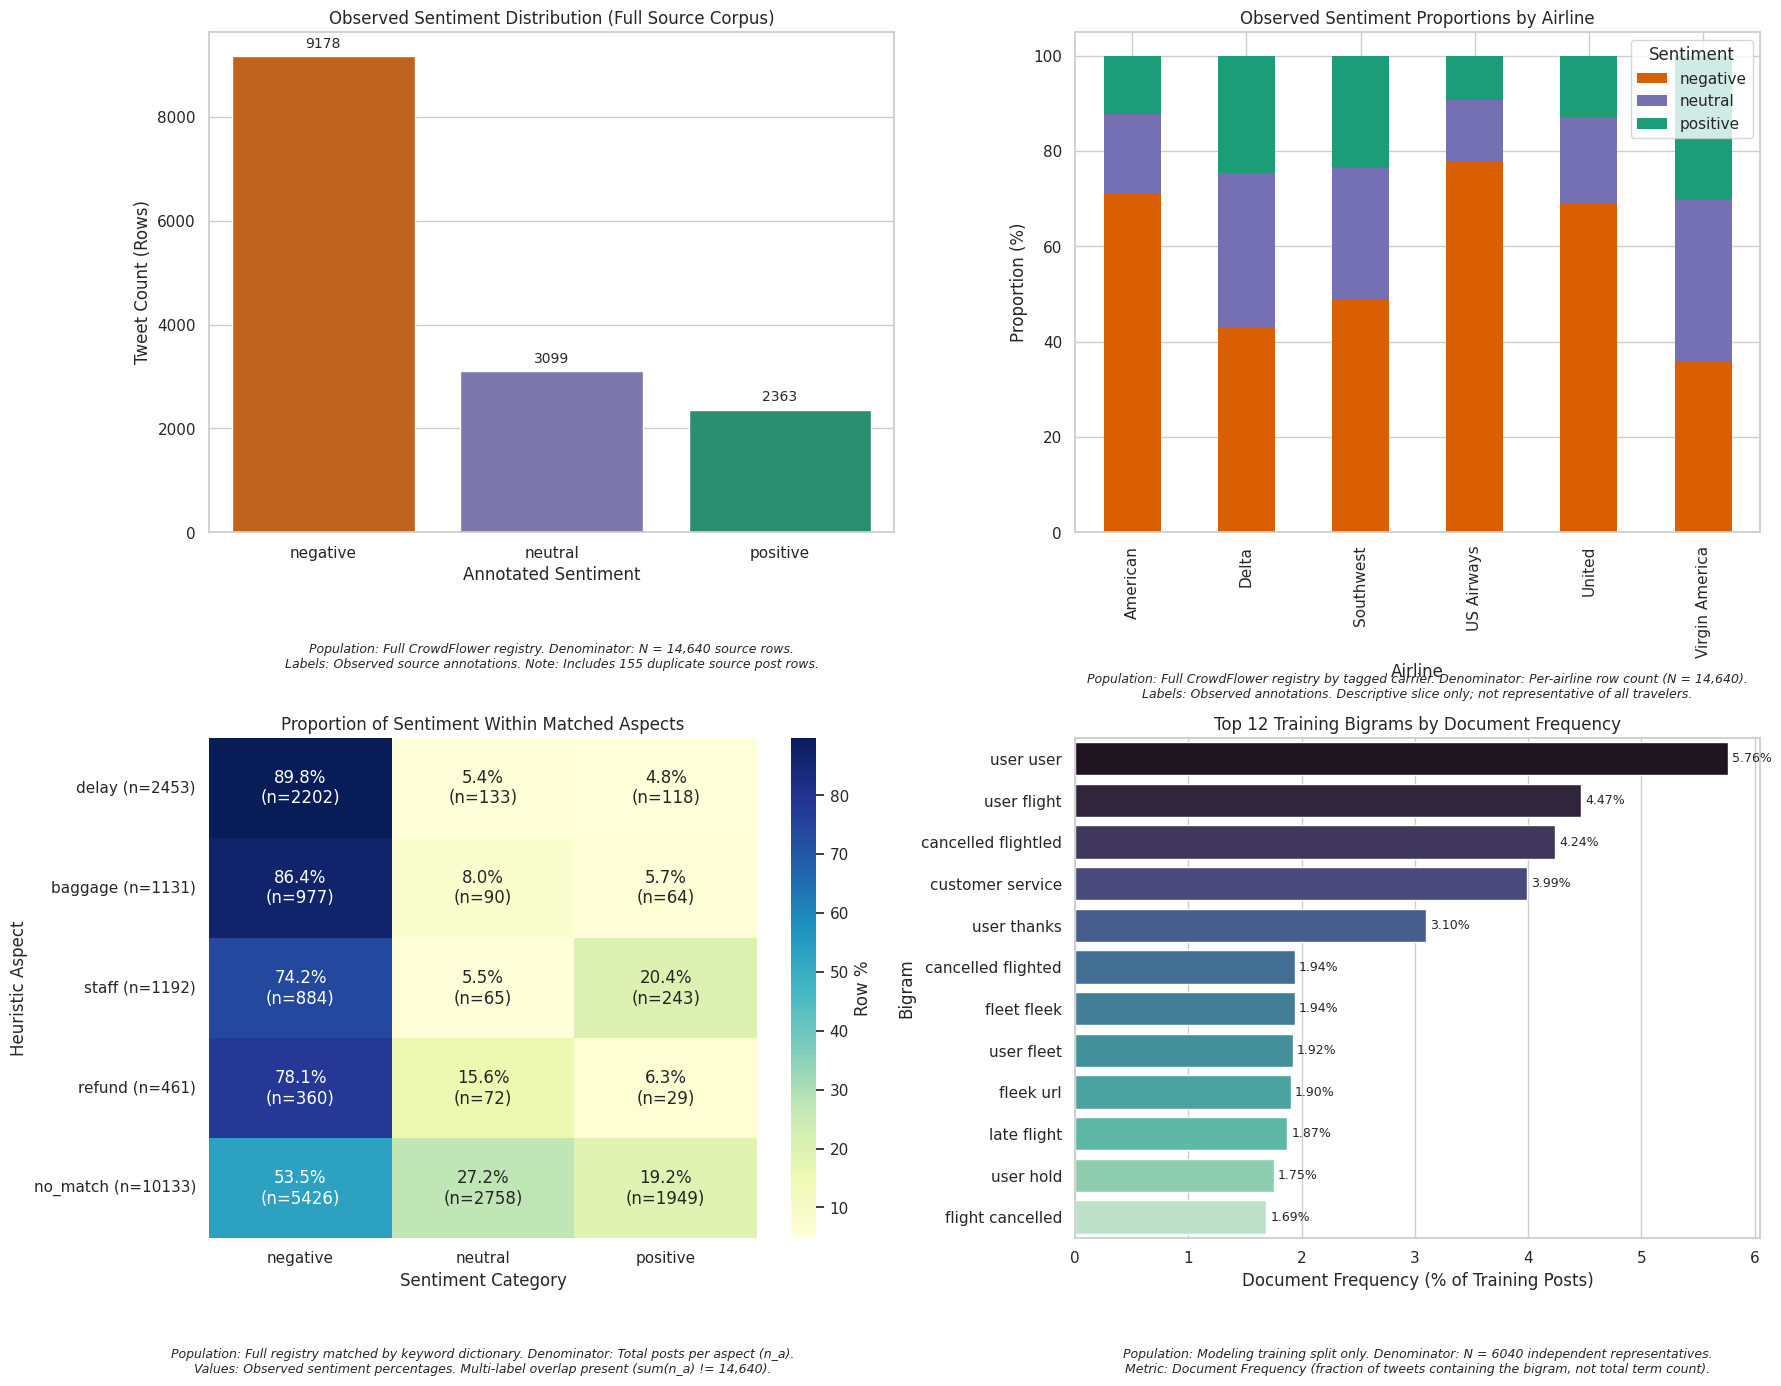

In [63]:

# 1. Aspect-by-Sentiment Crosstabulation (Full Source Registry)

# Note: Multi-label posts overlap; summed aspect counts exceed distinct post counts.
aspect_summary = []
classes_order = ['negative', 'neutral', 'positive']

for aspect in ASPECT_PATTERNS.keys():
    subset = df_stress[df_stress[f'tag_{aspect}']]
    n_a = len(subset)
    if n_a == 0:
        continue
    
    counts = subset['airline_sentiment'].value_counts()
    row = {'aspect': aspect, 'n_a': n_a}
    for c in classes_order:
        c_count = counts.get(c, 0)
        row[f'count_{c}'] = c_count
        row[f'pct_{c}'] = (c_count / n_a) * 100.0
    aspect_summary.append(row)

# No-match row
subset_none = df_stress[df_stress['tag_no_match']]
n_none = len(subset_none)
counts_none = subset_none['airline_sentiment'].value_counts()
row_none = {'aspect': 'no_match', 'n_a': n_none}
for c in classes_order:
    c_count = counts_none.get(c, 0)
    row_none[f'count_{c}'] = c_count
    row_none[f'pct_{c}'] = (c_count / n_none) * 100.0
aspect_summary.append(row_none)

df_aspect_table = pd.DataFrame(aspect_summary)

print("=== ASPECT-BY-SENTIMENT PROPORTIONS (FULL SOURCE REGISTRY) ===")
print(df_aspect_table[[
    'aspect', 'n_a', 
    'count_negative', 'pct_negative', 
    'count_neutral', 'pct_neutral', 
    'count_positive', 'pct_positive'
]].to_string(index=False))


# 2. Visualizations

CLASS_COLORS = {'negative': '#d95f02', 'neutral': '#7570b3', 'positive': '#1b9e77'}
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# Chart A: Observed Sentiment Count Bars (Source Registry)
# Total rows: 14,640 (includes 155 duplicate source posts per problem contract)
ax1 = axes[0, 0]
sentiment_counts = df_stress['airline_sentiment'].value_counts().reindex(classes_order)
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, ax=ax1, 
            palette=[CLASS_COLORS[c] for c in classes_order])
ax1.set_title("Observed Sentiment Distribution (Full Source Corpus)")
ax1.set_xlabel("Annotated Sentiment")
ax1.set_ylabel("Tweet Count (Rows)")
for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=10, xytext=(0, 4), textcoords='offset points')
ax1.text(0.5, -0.22, "Population: Full CrowdFlower registry. Denominator: N = 14,640 source rows.\nLabels: Observed source annotations. Note: Includes 155 duplicate source post rows.",
         ha='center', va='top', transform=ax1.transAxes, fontsize=9, style='italic')

# Chart B: 100% Stacked Sentiment Bars by Airline
ax2 = axes[0, 1]
airline_cross = pd.crosstab(df_stress['airline'], df_stress['airline_sentiment'], normalize='index')[classes_order] * 100
airline_cross.plot(kind='bar', stacked=True, ax=ax2, 
                   color=[CLASS_COLORS[c] for c in classes_order], edgecolor='none')
ax2.set_title("Observed Sentiment Proportions by Airline")
ax2.set_xlabel("Airline")
ax2.set_ylabel("Proportion (%)")
ax2.legend(title='Sentiment', loc='upper right')
ax2.text(0.5, -0.28, "Population: Full CrowdFlower registry by tagged carrier. Denominator: Per-airline row count (N = 14,640).\nLabels: Observed annotations. Descriptive slice only; not representative of all travelers.",
         ha='center', va='top', transform=ax2.transAxes, fontsize=9, style='italic')

# Chart C: Aspect-by-Sentiment Proportion Heatmap (n_a Displayed)
ax3 = axes[1, 0]
heatmap_data = df_aspect_table.set_index('aspect')[[f'pct_{c}' for c in classes_order]]
heatmap_data.columns = classes_order
labels_annot = np.array([
    [f"{val:.1f}%\n(n={df_aspect_table.loc[df_aspect_table['aspect']==asp, f'count_{c}'].values[0]})" 
     for c, val in row.items()]
    for asp, row in heatmap_data.iterrows()
])
sns.heatmap(heatmap_data, annot=labels_annot, fmt='', cmap='YlGnBu', ax=ax3, cbar_kws={'label': 'Row %'})
y_labels_with_na = [f"{row['aspect']} (n={row['n_a']})" for _, row in df_aspect_table.iterrows()]
ax3.set_yticklabels(y_labels_with_na, rotation=0)
ax3.set_title("Proportion of Sentiment Within Matched Aspects")
ax3.set_xlabel("Sentiment Category")
ax3.set_ylabel("Heuristic Aspect")
ax3.text(0.5, -0.22, "Population: Full registry matched by keyword dictionary. Denominator: Total posts per aspect (n_a).\nValues: Observed sentiment percentages. Multi-label overlap present (sum(n_a) != 14,640).",
         ha='center', va='top', transform=ax3.transAxes, fontsize=9, style='italic')

# Chart D: Training-Only Top Bigrams by Document Frequency (DF)
ax4 = axes[1, 1]
# Binary=True transforms counts to document occurrences (Document Frequency)
vec_df = CountVectorizer(ngram_range=(2, 2), max_features=12, stop_words='english', binary=True)
X_train_df = vec_df.fit_transform(df_train['text_clean'])
doc_freqs = X_train_df.sum(axis=0).A1
n_train_docs = len(df_train)
doc_freq_pct = (doc_freqs / n_train_docs) * 100.0

df_bigram_df = pd.DataFrame({
    'bigram': vec_df.get_feature_names_out(),
    'doc_freq_pct': doc_freq_pct
}).sort_values(by='doc_freq_pct', ascending=False)

sns.barplot(data=df_bigram_df, x='doc_freq_pct', y='bigram', ax=ax4, palette='mako')
ax4.set_title("Top 12 Training Bigrams by Document Frequency")
ax4.set_xlabel("Document Frequency (% of Training Posts)")
ax4.set_ylabel("Bigram")
for p in ax4.patches:
    ax4.annotate(f"{p.get_width():.2f}%", (p.get_width(), p.get_y() + p.get_height() / 2.),
                 ha='left', va='center', fontsize=9, xytext=(3, 0), textcoords='offset points')
ax4.text(0.5, -0.22, f"Population: Modeling training split only. Denominator: N = {n_train_docs} independent representatives.\nMetric: Document Frequency (fraction of tweets containing the bigram, not total term count).",
         ha='center', va='top', transform=ax4.transAxes, fontsize=9, style='italic')

plt.tight_layout()
plt.show()